In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys

sys.path.insert(
    0, "/content/drive/MyDrive/ArteryAI/src"
)

from config import *

print("Project connected:", ROOT)

Mounted at /content/drive
Project connected: /content/drive/MyDrive/ArteryAI


In [ ]:
!pip -q install datasets huggingface_hub

In [ ]:
from datasets import (
    load_dataset,
    get_dataset_config_names,
    get_dataset_split_names
)

REPO = "MedOtter/ARCADE"

configs = get_dataset_config_names(REPO)

print("Available configurations:", configs)

for cfg in configs:
    print(
        cfg,
        get_dataset_split_names(REPO, cfg)
    )

README.md:   0%|          | 0.00/2.46k [00:00<?, ?B/s]

Available configurations: ['syntax', 'stenosis']
syntax ['train', 'val', 'test']
stenosis ['train', 'val', 'test']


In [ ]:
cfg = next(
    (c for c in configs if "syntax" in c.lower()),
    configs[0]
)

split = get_dataset_split_names(REPO, cfg)[0]

preview = load_dataset(
    REPO,
    cfg,
    split=split,
    streaming=True
)

sample = next(iter(preview))

print("Configuration:", cfg)
print("Split:", split)
print("Columns:", list(sample.keys()))

for key, value in sample.items():
    print(key, type(value), getattr(value, "size", ""))

Configuration: syntax
Split: train
Columns: ['image', 'mask', 'image_id', 'file_name']
image <class 'PIL.PngImagePlugin.PngImageFile'> (512, 512)
mask <class 'PIL.PngImagePlugin.PngImageFile'> (512, 512)
image_id <class 'int'> 
file_name <class 'str'> 


###Download Dataset & Save Permanently

In [ ]:
from datasets import load_dataset, DatasetDict
from pathlib import Path

for task in ["syntax", "stenosis"]:

    save_path = RAW_DIR / task

    if (save_path / "dataset_dict.json").exists():
        print(f"{task}: Already downloaded")
        continue

    print(f"\nDownloading {task} dataset...")

    dataset = load_dataset(
        "MedOtter/ARCADE",
        task
    )

    dataset.save_to_disk(str(save_path))

    print(f"{task} saved successfully!")
    print(dataset)

syntax/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  225MB            

syntax/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

syntax/val-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 42.8MB            

syntax/val-00000-of-00001.parquet: downloading bytes:           |  0.00B            

syntax/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 53.0MB            

syntax/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (16 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/1000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/200 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/300 [00:00<?, ? examples/s]

stenosis saved successfully!
DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 1000
    })
    val: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 200
    })
    test: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 300
    })
})


###Load Saved Datasets

In [ ]:
from datasets import load_from_disk

artery_data = load_from_disk(
    str(RAW_DIR / "syntax")
)

stenosis_data = load_from_disk(
    str(RAW_DIR / "stenosis")
)

print("ARTERY SEGMENTATION DATASET")
print(artery_data)

print("\nSTENOSIS DETECTION DATASET")
print(stenosis_data)

ARTERY SEGMENTATION DATASET
DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 1000
    })
    val: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 200
    })
    test: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 300
    })
})

STENOSIS DETECTION DATASET
DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 1000
    })
    val: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 200
    })
    test: Dataset({
        features: ['image', 'mask', 'image_id', 'file_name'],
        num_rows: 300
    })
})


###Dataset Structure & Annotation Analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import json

for name, ds in [
    ("Artery Segmentation", artery_data),
    ("Stenosis Detection", stenosis_data)
]:

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    for split in ds:
        print(f"{split}: {len(ds[split])} images")

    sample = ds["train"][0]

    image = np.array(sample["image"])
    mask = np.array(sample["mask"])

    print("Image ID:", sample["image_id"])
    print("File Name:", sample["file_name"])
    print("Image Shape:", image.shape)
    print("Mask Shape:", mask.shape)
    print("Mask Mode:", sample["mask"].mode)
    print("Image dtype:", image.dtype)
    print("Mask dtype:", mask.dtype)
    print("Unique Mask Values:", np.unique(mask))


Artery Segmentation
train: 1000 images
val: 200 images
test: 300 images
Image ID: 922
File Name: 922.png
Image Shape: (512, 512, 3)
Mask Shape: (512, 512)
Mask Mode: L
Image dtype: uint8
Mask dtype: uint8
Unique Mask Values: [0 5 6 7 8]

Stenosis Detection
train: 1000 images
val: 200 images
test: 300 images
Image ID: 676
File Name: 676.png
Image Shape: (512, 512, 3)
Mask Shape: (512, 512)
Mask Mode: L
Image dtype: uint8
Mask dtype: uint8
Unique Mask Values: [ 0 26]


###Dataset Distribution Analysis

,Dataset,Split,Total Images
0,Artery Segmentation,train,1000
1,Artery Segmentation,val,200
2,Artery Segmentation,test,300
3,Stenosis Detection,train,1000
4,Stenosis Detection,val,200
5,Stenosis Detection,test,300


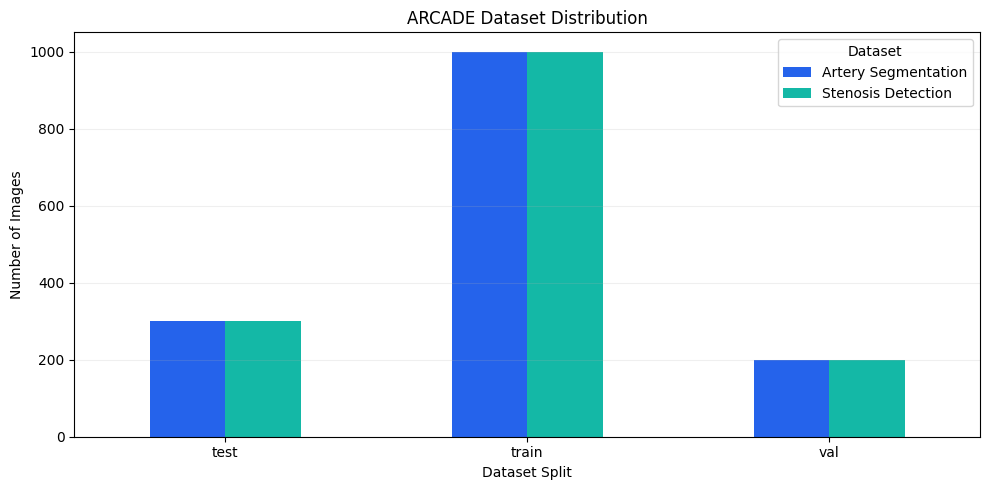

In [ ]:
records = []

for name, ds in [
    ("Artery Segmentation", artery_data),
    ("Stenosis Detection", stenosis_data)
]:

    for split in ds:
        records.append({
            "Dataset": name,
            "Split": split,
            "Total Images": len(ds[split])
        })

summary = pd.DataFrame(records)

display(summary)

summary.to_csv(
    M1 / "outputs/dataset_summary.csv",
    index=False
)

summary.pivot(
    index="Split",
    columns="Dataset",
    values="Total Images"
).plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2563EB", "#14B8A6"]
)

plt.title("ARCADE Dataset Distribution")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    M1 / "outputs/dataset_distribution.png",
    dpi=200
)

plt.show()

###Visualize Original Images, Masks & Overlays

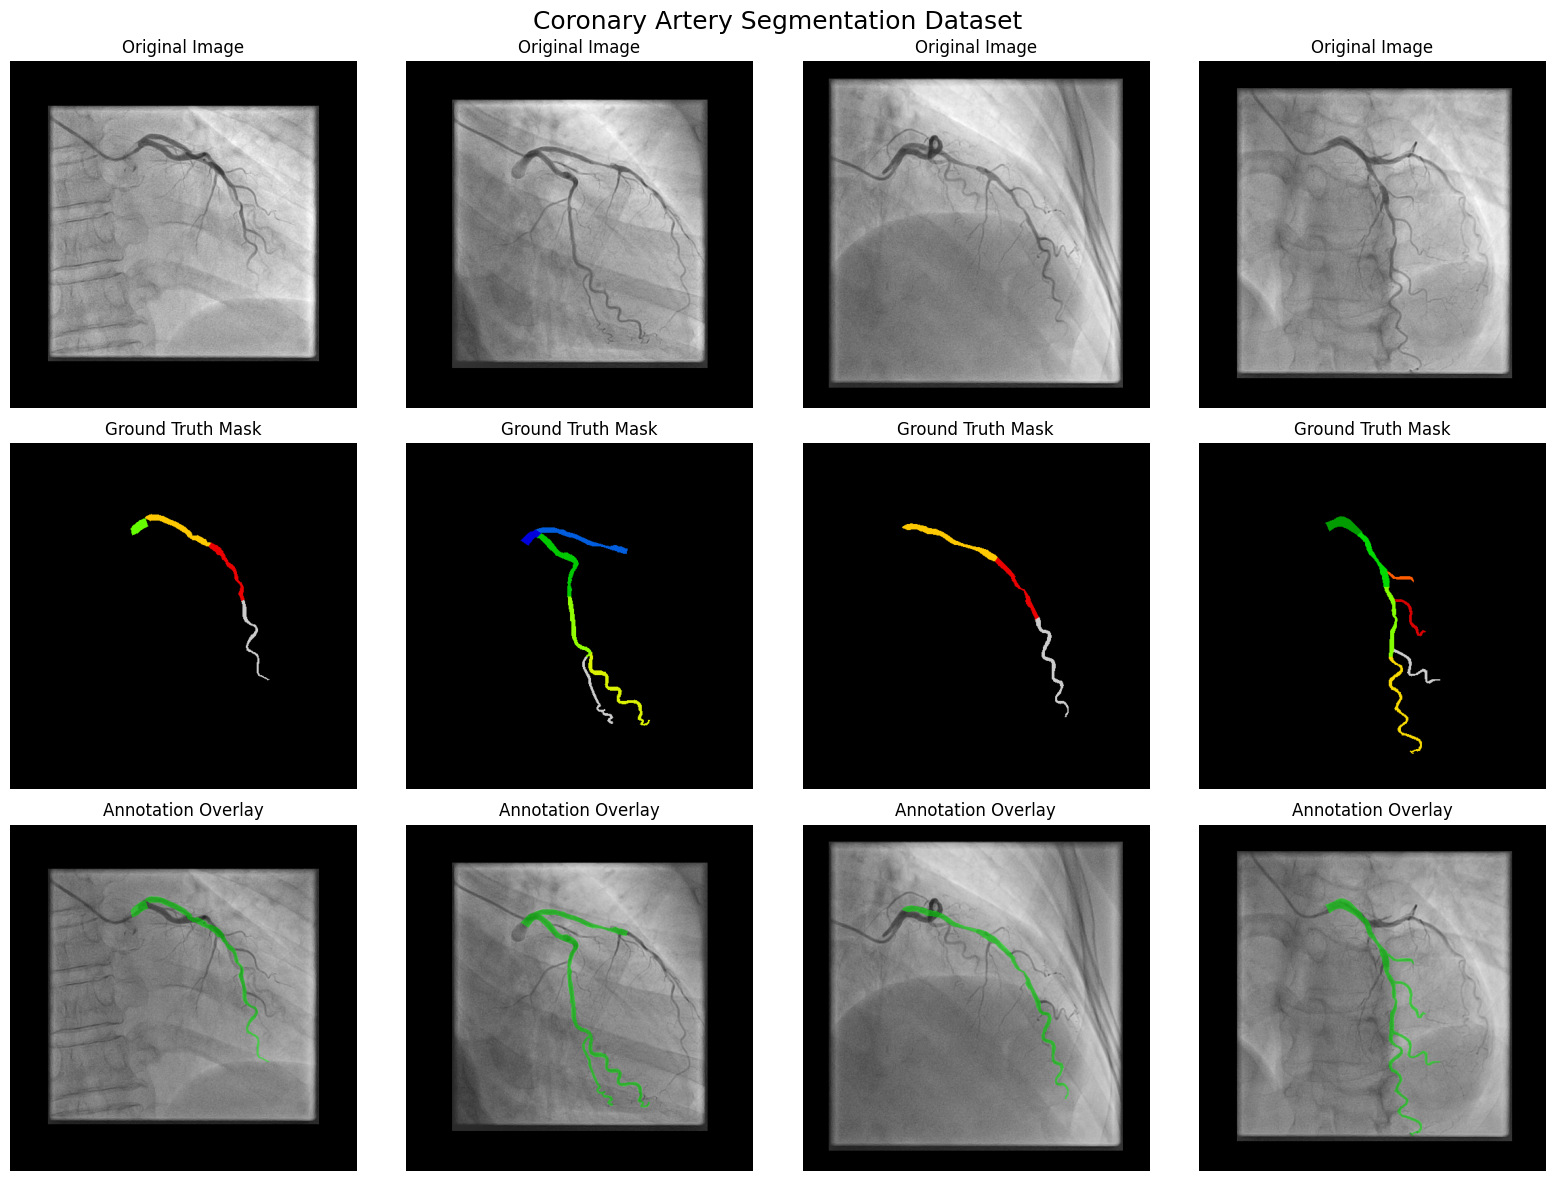

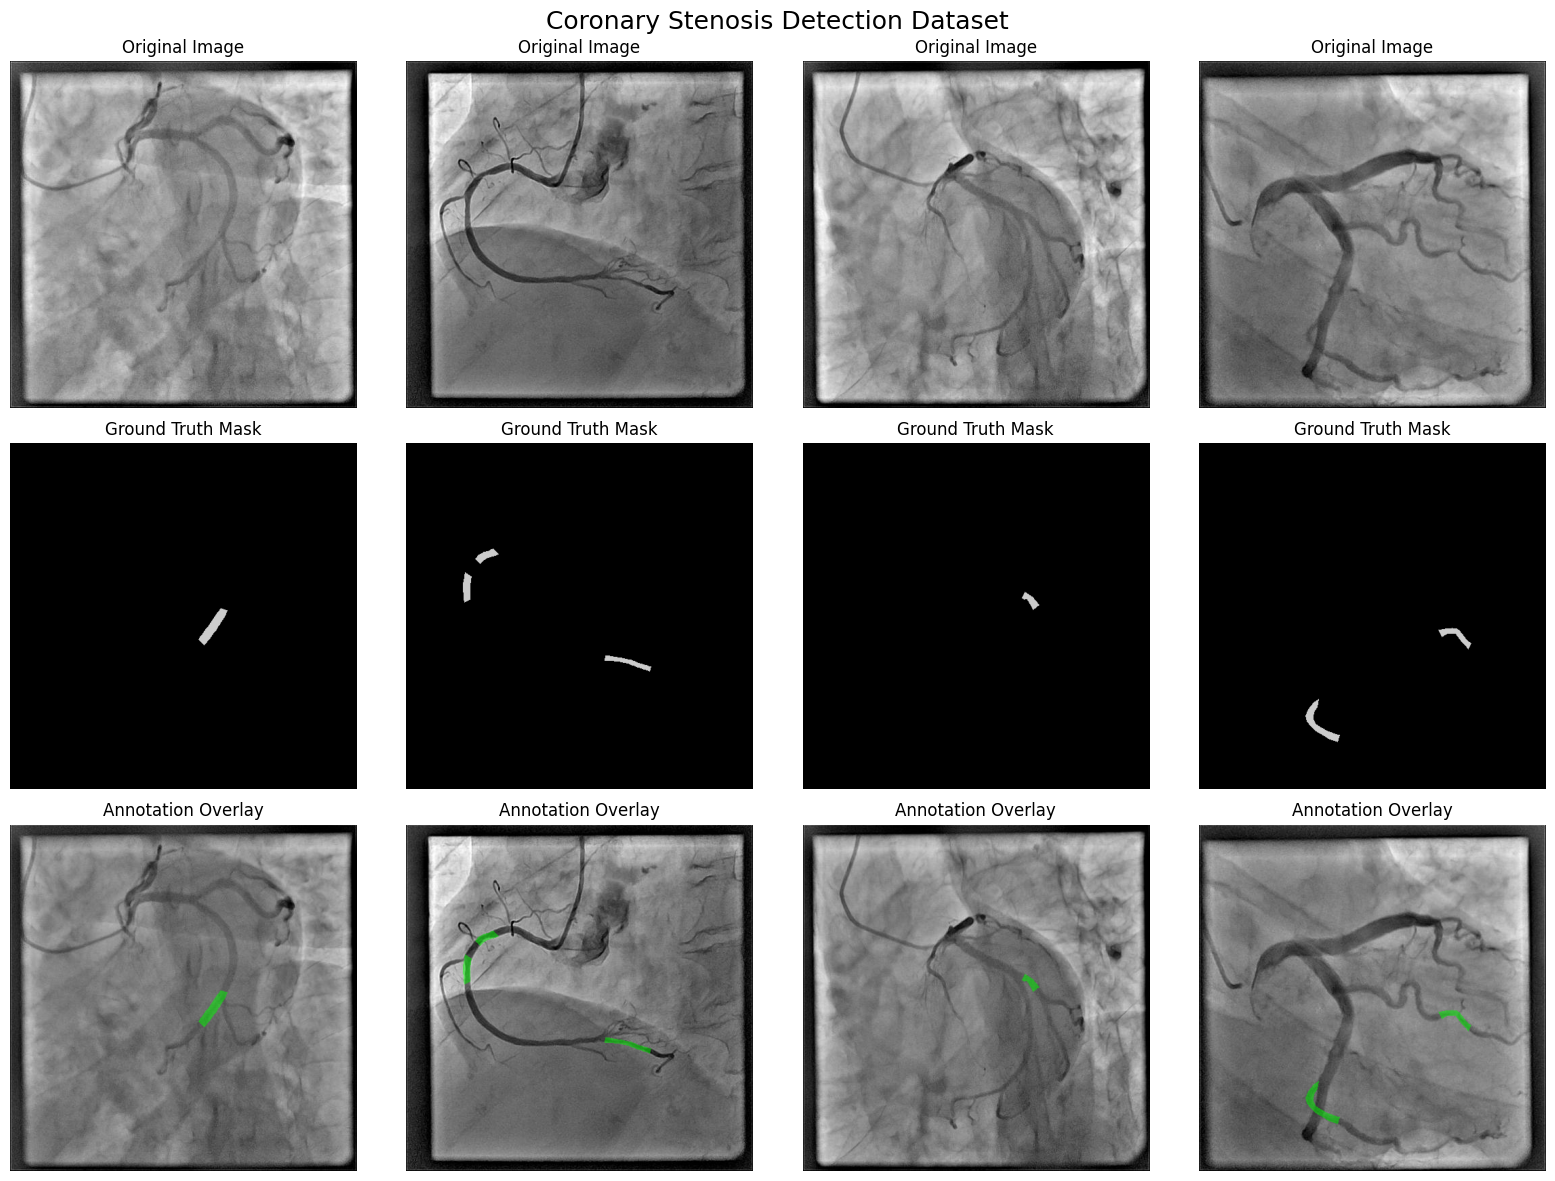

In [ ]:
def visualize_dataset(ds, title, filename):

    fig, axes = plt.subplots(
        3, 4, figsize=(16, 12)
    )

    for i in range(4):

        sample = ds["train"][i]

        image = np.array(
            sample["image"].convert("L")
        )

        mask = np.array(sample["mask"])

        if mask.ndim == 3:
            foreground = np.any(mask != 0, axis=-1)
        else:
            foreground = mask != 0

        overlay = cv2.cvtColor(
            image, cv2.COLOR_GRAY2RGB
        )

        overlay[foreground] = (
            0.5 * overlay[foreground] +
            0.5 * np.array([0, 255, 0])
        ).astype(np.uint8)

        axes[0, i].imshow(image, cmap="gray")
        axes[0, i].set_title("Original Image")

        axes[1, i].imshow(mask, cmap="nipy_spectral")
        axes[1, i].set_title("Ground Truth Mask")

        axes[2, i].imshow(overlay)
        axes[2, i].set_title("Annotation Overlay")

        for j in range(3):
            axes[j, i].axis("off")

    plt.suptitle(title, fontsize=18)
    plt.tight_layout()

    plt.savefig(
        M1 / "outputs" / filename,
        dpi=200
    )

    plt.show()


visualize_dataset(
    artery_data,
    "Coronary Artery Segmentation Dataset",
    "artery_dataset_visualization.png"
)

visualize_dataset(
    stenosis_data,
    "Coronary Stenosis Detection Dataset",
    "stenosis_dataset_visualization.png"
)

###Dataset Quality Validation

In [ ]:
from tqdm.auto import tqdm

quality_records = []

for task, ds in [
    ("syntax", artery_data),
    ("stenosis", stenosis_data)
]:

    for split in ds:

        for i in tqdm(
            range(len(ds[split])),
            desc=f"{task}-{split}"
        ):

            try:
                sample = ds[split][i]

                image = np.array(sample["image"])
                mask = np.array(sample["mask"])

                valid = (
                    image.size > 0
                    and mask.size > 0
                    and image.shape[:2] == mask.shape[:2]
                )

                quality_records.append({
                    "task": task,
                    "split": split,
                    "image_id": sample["image_id"],
                    "file_name": sample["file_name"],
                    "width": image.shape[1],
                    "height": image.shape[0],
                    "valid": valid,
                    "empty_mask": not np.any(mask),
                    "error": ""
                })

            except Exception as e:

                quality_records.append({
                    "task": task,
                    "split": split,
                    "image_id": i,
                    "valid": False,
                    "error": str(e)
                })

quality_df = pd.DataFrame(quality_records)

quality_df.to_csv(
    M1 / "outputs/dataset_quality_report.csv",
    index=False
)

print("Total checked:", len(quality_df))
print("Valid images:", quality_df["valid"].sum())
print("Invalid images:", (~quality_df["valid"]).sum())

display(quality_df.head())

syntax-train:   0%|          | 0/1000 [00:00<?, ?it/s]

syntax-val:   0%|          | 0/200 [00:00<?, ?it/s]

syntax-test:   0%|          | 0/300 [00:00<?, ?it/s]

stenosis-train:   0%|          | 0/1000 [00:00<?, ?it/s]

stenosis-val:   0%|          | 0/200 [00:00<?, ?it/s]

stenosis-test:   0%|          | 0/300 [00:00<?, ?it/s]

Total checked: 3000
Valid images: 3000
Invalid images: 0


,task,split,image_id,file_name,width,height,valid,empty_mask,error
0,syntax,train,922,922.png,512,512,True,False,
1,syntax,train,793,793.png,512,512,True,False,
2,syntax,train,782,782.png,512,512,True,False,
3,syntax,train,660,660.png,512,512,True,False,
4,syntax,train,708,708.png,512,512,True,False,


###Class Distribution & Imbalance Analysis

Analyzing artery labels:   0%|          | 0/1000 [00:00<?, ?it/s]

,Class ID,Pixel Count,Percentage
0,0,253576361,96.731705
1,1,664435,0.253462
2,2,686727,0.261966
3,3,661957,0.252517
4,4,480566,0.183321
5,5,591829,0.225765
6,6,816901,0.311623
7,7,685677,0.261565
8,8,570436,0.217604
9,9,470633,0.179532


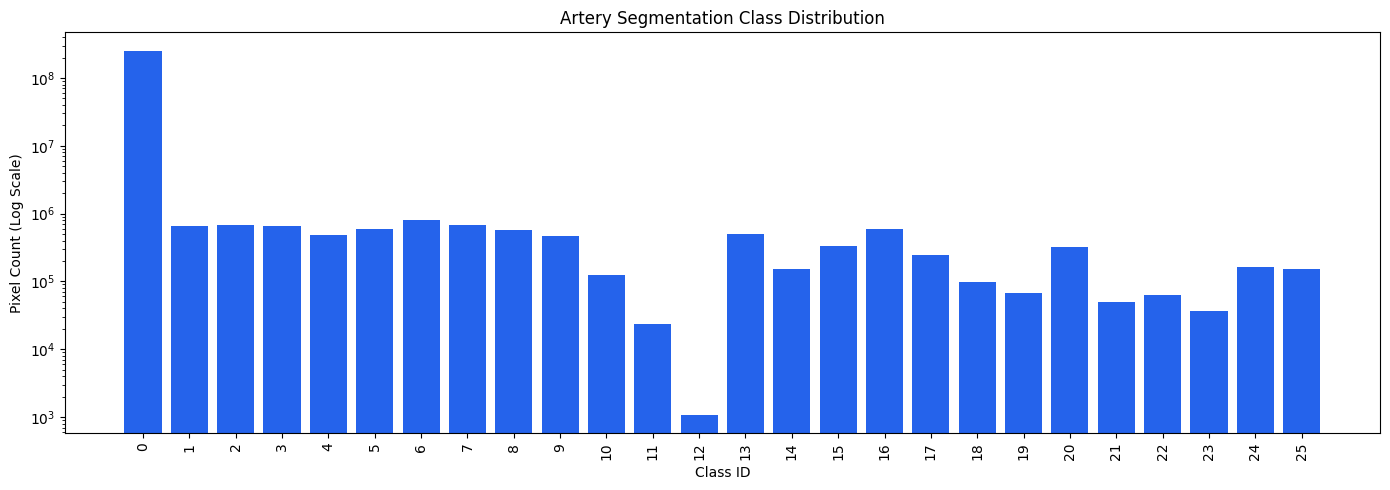

In [ ]:
from collections import Counter

class_counts = Counter()

for sample in tqdm(
    artery_data["train"],
    desc="Analyzing artery labels"
):

    mask = np.array(sample["mask"])

    if mask.ndim != 2:
        raise ValueError(
            "Mask is not a single-channel label map. "
            "Color-to-class mapping required."
        )

    labels, counts = np.unique(
        mask, return_counts=True
    )

    for label, count in zip(labels, counts):
        class_counts[int(label)] += int(count)

class_df = pd.DataFrame(
    sorted(class_counts.items()),
    columns=["Class ID", "Pixel Count"]
)

class_df["Percentage"] = (
    class_df["Pixel Count"] /
    class_df["Pixel Count"].sum()
) * 100

display(class_df)

class_df.to_csv(
    M1 / "outputs/class_distribution.csv",
    index=False
)

plt.figure(figsize=(14, 5))

plt.bar(
    class_df["Class ID"].astype(str),
    class_df["Pixel Count"],
    color="#2563EB"
)

plt.yscale("log")
plt.title("Artery Segmentation Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Pixel Count (Log Scale)")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig(
    M1 / "outputs/class_distribution.png",
    dpi=200
)

plt.show()


###Combined Dataset Validation

In [ ]:
from collections import Counter
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

quality_records = []
class_counts = {}
all_labels = {}

for task, ds in [
    ("syntax", artery_data),
    ("stenosis", stenosis_data)
]:

    class_counts[task] = Counter()
    all_labels[task] = set()

    for split in ["train", "val", "test"]:

        for i in tqdm(
            range(len(ds[split])),
            desc=f"{task}-{split}"
        ):

            try:
                sample = ds[split][i]

                image = np.array(sample["image"])
                mask = np.array(sample["mask"])

                valid = (
                    image.size > 0
                    and mask.size > 0
                    and mask.ndim == 2
                    and image.shape[:2] == mask.shape
                )

                labels, counts = np.unique(
                    mask, return_counts=True
                )

                all_labels[task].update(
                    int(x) for x in labels
                )

                if split == "train" and valid:

                    for label, count in zip(labels, counts):

                        class_counts[task][int(label)] += int(count)

                quality_records.append({
                    "task": task,
                    "split": split,
                    "image_id": sample["image_id"],
                    "file_name": sample["file_name"],
                    "valid": valid,
                    "empty_mask": not np.any(mask),
                    "foreground_percentage":
                        float(np.mean(mask > 0) * 100),
                    "error": ""
                })

            except Exception as e:

                quality_records.append({
                    "task": task,
                    "split": split,
                    "image_id": i,
                    "valid": False,
                    "error": str(e)
                })

quality_df = pd.DataFrame(quality_records)

quality_df.to_csv(
    M1 / "outputs/dataset_quality_report.csv",
    index=False
)

print("Total checked:", len(quality_df))
print("Valid images:", quality_df["valid"].sum())
print("Invalid images:", (~quality_df["valid"]).sum())

for task in all_labels:

    print(
        task,
        "All labels:",
        sorted(all_labels[task])
    )

display(quality_df.head())

syntax-train:   0%|          | 0/1000 [00:00<?, ?it/s]

syntax-val:   0%|          | 0/200 [00:00<?, ?it/s]

syntax-test:   0%|          | 0/300 [00:00<?, ?it/s]

stenosis-train:   0%|          | 0/1000 [00:00<?, ?it/s]

stenosis-val:   0%|          | 0/200 [00:00<?, ?it/s]

stenosis-test:   0%|          | 0/300 [00:00<?, ?it/s]

Total checked: 3000
Valid images: 3000
Invalid images: 0
syntax All labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
stenosis All labels: [0, 26]


,task,split,image_id,file_name,valid,empty_mask,foreground_percentage,error
0,syntax,train,922,922.png,True,False,0.917053,
1,syntax,train,793,793.png,True,False,1.596069,
2,syntax,train,782,782.png,True,False,1.011276,
3,syntax,train,660,660.png,True,False,1.459122,
4,syntax,train,708,708.png,True,False,1.907730,


###Generate Class Distribution Graphs

,Class_ID,Pixel_Count,Percentage
0,0,253576361,96.731705
1,1,664435,0.253462
2,2,686727,0.261966
3,3,661957,0.252517
4,4,480566,0.183321
5,5,591829,0.225765
6,6,816901,0.311623
7,7,685677,0.261565
8,8,570436,0.217604
9,9,470633,0.179532


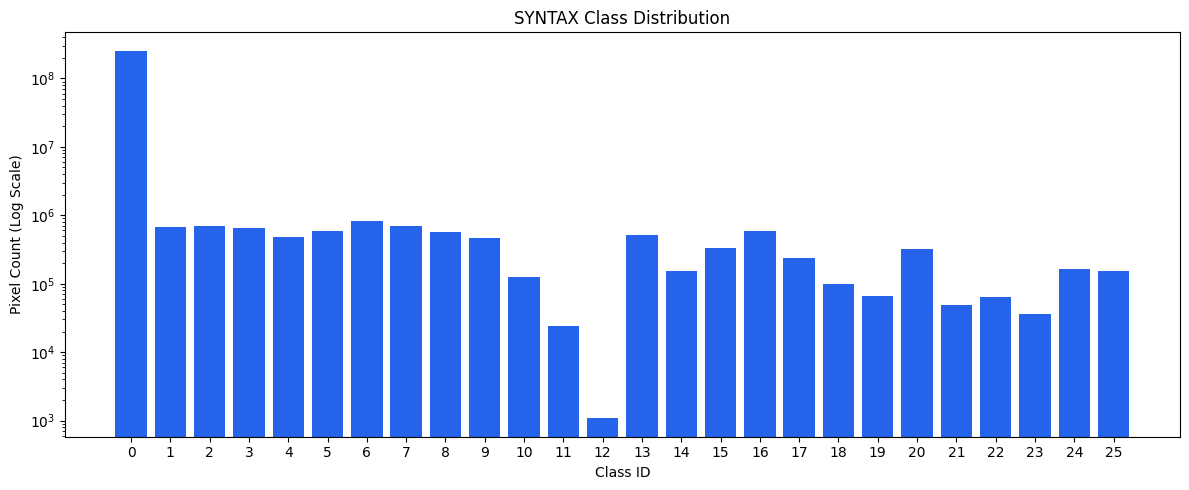

,Class_ID,Pixel_Count,Percentage
0,0,260066351,99.20744
1,26,2077649,0.79256


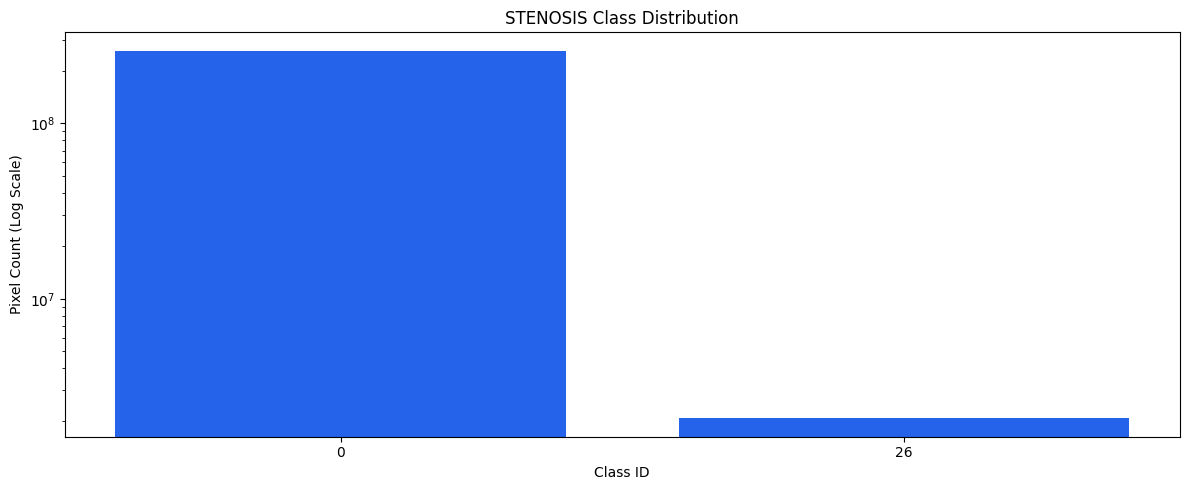

In [ ]:
for task, counter in class_counts.items():

    class_df = pd.DataFrame(
        sorted(counter.items()),
        columns=["Class_ID", "Pixel_Count"]
    )

    class_df["Percentage"] = (
        class_df["Pixel_Count"] /
        class_df["Pixel_Count"].sum()
    ) * 100

    display(class_df)

    class_df.to_csv(
        M1 / f"outputs/{task}_class_distribution.csv",
        index=False
    )

    plt.figure(figsize=(12, 5))

    plt.bar(
        class_df["Class_ID"].astype(str),
        class_df["Pixel_Count"],
        color="#2563EB"
    )

    plt.yscale("log")
    plt.title(f"{task.upper()} Class Distribution")
    plt.xlabel("Class ID")
    plt.ylabel("Pixel Count (Log Scale)")
    plt.tight_layout()

    plt.savefig(
        M1 / f"outputs/{task}_class_distribution.png",
        dpi=200
    )

    plt.show()

###Save Class Mapping

In [ ]:
class_mapping = {}

for task, labels in all_labels.items():

    labels = sorted(labels)

    assert 0 in labels, "Background label missing"

    class_mapping[task] = {
        str(label): index
        for index, label in enumerate(labels)
    }

with open(DATA_DIR / "class_mapping.json", "w") as f:

    json.dump(class_mapping, f, indent=4)

print(json.dumps(class_mapping, indent=4))

{
    "syntax": {
        "0": 0,
        "1": 1,
        "2": 2,
        "3": 3,
        "4": 4,
        "5": 5,
        "6": 6,
        "7": 7,
        "8": 8,
        "9": 9,
        "10": 10,
        "11": 11,
        "12": 12,
        "13": 13,
        "14": 14,
        "15": 15,
        "16": 16,
        "17": 17,
        "18": 18,
        "19": 19,
        "20": 20,
        "21": 21,
        "22": 22,
        "23": 23,
        "24": 24,
        "25": 25
    },
    "stenosis": {
        "0": 0,
        "26": 1
    }
}
